# 1. Problema de Secuenciación de Tareas

Hugo André Meza Fierros - A00841695

Gil Brandon García Contreras - A01254164

Jesús Alejandro Pérez Granados - A01253993

Santiago Hernández Jiménez - A01662307

Luis Santiago Benvenuto Valerdi - A01286400

---

Este notebook resuelve el problema de secuenciación de tareas en una sola máquina planteado en la Tarea. La instancia consta de $5$ tareas, cada una con su tiempo de procesamiento ($t_i$), fecha límite ($d_i$), costo de retención por unidad de tiempo ($h_i$) y costo de penalización por unidad de tiempo ($c_i$). El objetivo es determinar la secuencia de procesamiento que minimiza el costo total por adelanto y retraso, para lo cual se formula y se resuelve un modelo de programación lineal entera mixta.

## 1.1 Definición del problema

Dado un conjunto $M = \{1, 2, ... , m\} $ de tareas que se van a secuenciar en una sola máquina, cada tarea $i \in M$ tiene un tiempo de procesamiento $t_i$ y una fecha límite $d_i$ para ser realizada. Si la tarea $i$ se completa antes de la fecha límite, incurre en un costo de retención $h_i$ por unidad de tiempo. Una tarea retardada $i$ da como resultado un costo de penalización $c_i$ por unidad de tiempo

| Tarea ($i$) | $t_i$ | $d_i$ | $h_i$ | $c_i$ |
| :---: | :---: | :---: | :---: | :---: |
| 1 | 10 | 15 | 3 | 10 |
| 2 | 8 | 20 | 2 | 22 |
| 3 | 6 | 10 | 5 | 10 |
| 4 | 7 | 30 | 4 | 8 |
| 5 | 4 | 12 | 6 | 15 |

## 1.2 Modelo matemático

In [20]:
from docplex.mp.model import Model

# 1. Inicializar el modelo de DOcplex
mdl = Model(name="Single_Machine_Scheduling")

# 2. Conjunto de tareas (M)
M = [1, 2, 3, 4, 5]

# 3. Parámetros de las tareas
t = {1: 10, 2: 8,  3: 6,  4: 7,  5: 4}   # Tiempos de procesamiento (t_i)
d = {1: 15, 2: 20, 3: 10, 4: 30, 5: 12}  # Fechas límite (d_i)
h = {1: 3,  2: 2,  3: 5,  4: 4,  5: 6}   # Costos por adelanto (h_i)
c = {1: 10, 2: 22, 3: 10, 4: 8,  5: 15}  # Costos por retraso (c_i)

# 4. Parámetro Big-M (V)
# Una cota superior ajustada y segura para este problema es la suma de 
# todos los tiempos de procesamiento.
V = sum(t.values()) + max(d.values())  # Cota superior para el tiempo de finalización

In [21]:
# --- 2. Variables de Decisión ---
# Variables continuas para finalización, adelanto y retraso
C = mdl.continuous_var_dict(M, name="C")
E = mdl.continuous_var_dict(M, name="E")
T = mdl.continuous_var_dict(M, lb=0, name="T") # lb=0 por defecto, pero es buena práctica

# Variables binarias y_ij solo para i < j
pares = [(i, j) for i in M for j in M if i < j]
y = mdl.binary_var_dict(pares, name="y")

# --- 3. Función Objetivo ---
# Minimizar el costo total por adelanto y retraso
mdl.minimize(mdl.sum(h[i] * E[i] + c[i] * T[i] for i in M))

# --- 4. Restricciones ---
# 4.1 Cálculo de adelanto (E_i) y retraso (T_i)
for i in M:
    mdl.add_constraint(E[i] >= d[i] - C[i], ctname=f"Earliness_{i}")
    mdl.add_constraint(T[i] >= C[i] - d[i], ctname=f"Tardiness_{i}")

# 4.2 Tiempo mínimo de finalización (ninguna termina antes de lo que tarda)
for i in M:
    mdl.add_constraint(C[i] >= t[i], ctname=f"Min_Completion_{i}")

# 4.3 Restricciones disyuntivas (evitar traslape en la máquina)
for (i, j) in pares:
    # Si y_ij = 1, la tarea i precede a la j
    mdl.add_constraint(C[j] >= C[i] + t[j] - V * (1 - y[i, j]), ctname=f"Disyuntiva_1_{i}_{j}")
    # Si y_ij = 0, la tarea j precede a la i
    mdl.add_constraint(C[i] >= C[j] + t[i] - V * y[i, j], ctname=f"Disyuntiva_2_{i}_{j}")

# --- 5. Resolución y Resultados ---
solucion = mdl.solve(log_output=False) # Cambia a True si quieres ver el proceso del solver


In [22]:
import time

if solucion:
    # 1. Extraer el Costo Objetivo
    costo_optimo = solucion.get_objective_value()
    
    # 2. Extraer el Tiempo de Cómputo del Solver
    # solve_details.time te da el tiempo exacto que CPLEX invirtió buscando la solución
    tiempo_cplex = mdl.solve_details.time
    
    # 3. Extraer la Secuencia
    secuencia_optima = sorted(M, key=lambda i: solucion.get_value(C[i]))
    
    # Guardar los resultados en un diccionario para la comparación
    resultados_exactos = {
        "metodo": "DOcplex (MIP)",
        "costo_total": costo_optimo,
        "tiempo_segundos": round(tiempo_cplex, 4),
        "secuencia": secuencia_optima
    }
    
    print("--- MÉTRICAS PARA COMPARACIÓN ---")
    print(f"Método: {resultados_exactos['metodo']}")
    print(f"Estado de la solución: {mdl.get_solve_status()}")
    print(f"Costo Óptimo: {resultados_exactos['costo_total']}")
    print(f"Tiempo de Cómputo: {resultados_exactos['tiempo_segundos']} segundos")
    print(f"Secuencia Óptima: {resultados_exactos['secuencia']}")

    secuencia = sorted(M, key=lambda i: solucion.get_value(C[i]))
    for i in secuencia:
            tiempo_inicio = solucion.get_value(C[i]) - t[i]
            finalizacion = solucion.get_value(C[i])
            adelanto = solucion.get_value(E[i])
            retraso = solucion.get_value(T[i])
            
            print(f"Tarea {i}: Inicio = {tiempo_inicio:2.0f} | Fin = {finalizacion:2.0f} | "
                  f"Límite = {d[i]:2.0f} | Adelanto = {adelanto:2.0f} | Retraso = {retraso:2.0f}")
else:
    print("No se encontró solución factible para evaluar.")

--- MÉTRICAS PARA COMPARACIÓN ---
Método: DOcplex (MIP)
Estado de la solución: JobSolveStatus.OPTIMAL_SOLUTION
Costo Óptimo: 205.99999999999997
Tiempo de Cómputo: 0.109 segundos
Secuencia Óptima: [3, 5, 2, 1, 4]
Tarea 3: Inicio =  0 | Fin =  6 | Límite = 10 | Adelanto =  4 | Retraso =  0
Tarea 5: Inicio =  6 | Fin = 10 | Límite = 12 | Adelanto =  2 | Retraso =  0
Tarea 2: Inicio = 10 | Fin = 18 | Límite = 20 | Adelanto =  2 | Retraso =  0
Tarea 1: Inicio = 18 | Fin = 28 | Límite = 15 | Adelanto =  0 | Retraso = 13
Tarea 4: Inicio = 28 | Fin = 35 | Límite = 30 | Adelanto =  0 | Retraso =  5


## 1.3 Algoritmo genético

In [57]:
import numpy as np
import time

def objective_function(t, d, h, c, secuencia):
    tiempo = 0
    costo_total = 0
    
    for tarea in secuencia:
        tiempo += t[tarea]
        adelanto = max(d[tarea] - tiempo, 0)
        retraso = max(tiempo - d[tarea], 0)
        costo_total += h[tarea] * adelanto + c[tarea] * retraso
    
    return costo_total

def fitness_function(t, d, h, c, secuencia):
    return objective_function(t, d, h, c, secuencia)


def torneo(fitness_values, k=3):
    """Selección por torneo (minimización). Devuelve dos padres distintos."""
    fitness_values = np.asarray(fitness_values)

    def ganador():
        participantes = np.random.choice(len(fitness_values), size=k, replace=False)
        return participantes[np.argmin(fitness_values[participantes])]

    p1 = ganador()
    p2 = ganador()
    while p2 == p1:
        p2 = ganador()
    return p1, p2

def cruza_mitad(padre1, padre2):
    """Cruza de un punto a la mitad (n//2) preservando la permutación.
    El hijo hereda la parte izquierda de un padre y completa con las
    tareas faltantes en el orden en que aparecen en el otro padre."""
    mitad = len(padre1) // 2

    def construir_hijo(a, b):
        izquierda = a[:mitad]
        # Tareas que faltan, en el orden en que aparecen en el otro padre
        resto = [gen for gen in b if gen not in izquierda]
        return np.concatenate((izquierda, resto))

    hijo1 = construir_hijo(padre1, padre2)
    hijo2 = construir_hijo(padre2, padre1)
    return hijo1, hijo2

def mutacion(hijo, tasa_mutacion=0.05):
    """Mutación por intercambio (swap) preservando la permutación.
    Cada gen tiene probabilidad tasa_mutacion de intercambiarse
    con otro gen elegido al azar."""
    hijo_mutado = np.copy(hijo)
    n = len(hijo_mutado)
    for i in range(n):
        if np.random.rand() < tasa_mutacion:
            # Elegir otra posición distinta de i
            j = np.random.choice([k for k in range(n) if k != i])
            hijo_mutado[i], hijo_mutado[j] = hijo_mutado[j], hijo_mutado[i]
    return hijo_mutado

In [82]:
def ejecutar_genetico(t, d, h, c, M, num_vectores=10, num_iteraciones=1500, tasa_mutacion = 0.05):
    n = len(M) # Número de tareas
    
    # Inicialización con permutación
    poblacion_actual = np.array([np.random.permutation(M) for _ in range(num_vectores)])
    
    # Evaluar la población inicial
    fitness_poblacion = np.array([fitness_function(t, d, h, c, ind) for ind in poblacion_actual])

    historial_mejor_fitness = []

    # Iniciar cronómetro
    start_time = time.time()
    
    # Ciclo de Estado Estacionario
    for _ in range(num_iteraciones):
        
        # 1. Selección (Torneo)
        padre1, padre2 = torneo(fitness_poblacion)
        
        # 2. Cruza (1 punto a la mitad)
        hijo1, hijo2 = cruza_mitad(poblacion_actual[padre1], poblacion_actual[padre2])
        
        # 3. Mutación
        hijo1 = mutacion(hijo1, tasa_mutacion)
        hijo2 = mutacion(hijo2, tasa_mutacion)
        
        # 4. Evaluar hijos
        fit_h1 = fitness_function(t, d, h, c, hijo1)
        fit_h2 = fitness_function(t, d, h, c, hijo2)
        
        # 5. REEMPLAZO: Encontrar los 2 peores individuos
        # argsort ordena de menor a mayor fitness, tomamos los 2 primeros índices
        indices_peores = np.argsort(fitness_poblacion)[num_vectores - 2:num_vectores]
        
        # Sustituir a los 2 peores con los nuevos hijos
        poblacion_actual[indices_peores[0]] = hijo1
        fitness_poblacion[indices_peores[0]] = fit_h1
        
        poblacion_actual[indices_peores[1]] = hijo2
        fitness_poblacion[indices_peores[1]] = fit_h2

        mejor_actual = np.min(fitness_poblacion)
        historial_mejor_fitness.append(mejor_actual)
        
    # Detener cronómetro
    end_time = time.time()
    tiempo_cpu = end_time - start_time
    
    # Buscar el mejor individuo histórico que quedó en la población final
    mejor_idx = np.argmin(fitness_poblacion)
    mejor_vector = poblacion_actual[mejor_idx]
    mejor_fitness = fitness_poblacion[mejor_idx]
    mejor_valor = objective_function(t, d, h, c, mejor_vector)
    
    return (mejor_vector, mejor_valor, mejor_fitness, tiempo_cpu, 
            poblacion_actual, fitness_poblacion, historial_mejor_fitness)

In [ ]:
z_opt = costo_optimo 

for _ in range(30):
    (vec1, val, fit1, tiempo1, 
    pob_final1, fit_pob_final1, historial1) = ejecutar_genetico(t, d, h, c, M)
    brecha1 = (val - z_opt) / z_opt * 100 * 100
    print(f"Mejor Valor: {val}  | Tiempo CPU: {tiempo1:.4f}s | Diferencia vs Óptimo: {brecha1:.2f}%")

Mejor Valor: 206  | Tiempo CPU: 0.0840s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0750s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0686s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0732s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0746s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0736s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0726s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0753s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0718s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0752s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0761s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0718s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0719s | Diferencia vs Óptimo: -0.00%
Mejor Valor: 206  | Tiempo CPU: 0.0745s | Diferencia vs Óptimo: -0.00%
Mejor 

## 1.4 Comparación de resultados

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools, time

N_CORRIDAS = 30
N_ITER = 1500
POB = 10
z_opt = round(costo_optimo)          # 206

corridas, historiales = [], []
for semilla in range(N_CORRIDAS):
    np.random.seed(semilla)
    vec, val, fit, tiempo, pob, fit_pob, hist = ejecutar_genetico(
        t, d, h, c, M, num_vectores=POB, num_iteraciones=N_ITER)
    hist = np.array(hist)
    alcanzo = hist <= z_opt
    it_opt = int(np.argmax(alcanzo)) + 1 if alcanzo.any() else np.nan
    corridas.append({
        "Corrida": semilla + 1,
        "Costo": val,
        "Secuencia": [int(x) for x in vec],
        "Tiempo (s)": tiempo,
        "Gap (%)": (val - z_opt) / z_opt * 100,
        "Iter. al óptimo": it_opt,
    })
    historiales.append(hist)

df_ga = pd.DataFrame(corridas)
H = np.vstack(historiales)           # (30, 1500)
df_ga.head()

,Corrida,Costo,Secuencia,Tiempo (s),Gap (%),Iter. al óptimo
0,1,206,"[3, 5, 2, 1, 4]",0.067626,0.0,19
1,2,206,"[3, 5, 2, 1, 4]",0.067638,0.0,16
2,3,206,"[3, 5, 2, 1, 4]",0.068623,0.0,14
3,4,206,"[3, 5, 2, 1, 4]",0.068557,0.0,30
4,5,206,"[3, 5, 2, 1, 4]",0.068608,0.0,26


In [70]:
tasa_exito = (df_ga["Costo"] == z_opt).mean() * 100

stats = pd.DataFrame({
    "Métrica": ["Mejor costo", "Costo promedio", "Peor costo", "Desv. estándar",
                "Tasa de éxito (%)", "Tiempo promedio (s)",
                "Iteraciones al óptimo (promedio)", "Iteraciones al óptimo (máx.)",
                "Gap promedio (%)"],
    "Valor": [df_ga["Costo"].min(), df_ga["Costo"].mean(), df_ga["Costo"].max(),
              df_ga["Costo"].std(), tasa_exito, df_ga["Tiempo (s)"].mean(),
              df_ga["Iter. al óptimo"].mean(), df_ga["Iter. al óptimo"].max(),
              df_ga["Gap (%)"].mean()]
})
print(stats.to_string(index=False))
print("\nSecuencias distintas encontradas:", df_ga["Secuencia"].apply(tuple).unique())

# Para LaTeX (si falla, pip install jinja2):
# print(stats.to_latex(index=False, float_format="%.3f"))

                         Métrica      Valor
                     Mejor costo 206.000000
                  Costo promedio 206.000000
                      Peor costo 206.000000
                  Desv. estándar   0.000000
               Tasa de éxito (%) 100.000000
             Tiempo promedio (s)   0.070025
Iteraciones al óptimo (promedio)  29.966667
    Iteraciones al óptimo (máx.)  85.000000
                Gap promedio (%)   0.000000

Secuencias distintas encontradas: [(3, 5, 2, 1, 4)]


In [71]:
def programacion(sec):
    filas, tiempo = [], 0
    for i in sec:
        ini = tiempo
        tiempo += t[i]
        E = max(d[i] - tiempo, 0)
        T = max(tiempo - d[i], 0)
        filas.append({"Tarea": i, "Inicio": ini, "Fin": tiempo, "d_i": d[i],
                      "Adelanto": E, "Retraso": T,
                      "Costo retención": h[i] * E, "Costo penalización": c[i] * T,
                      "Costo": h[i] * E + c[i] * T})
    return pd.DataFrame(filas)

mejor_fila = df_ga.loc[df_ga["Costo"].idxmin()]
sec_ga = mejor_fila["Secuencia"]
prog_ga = programacion(sec_ga)
print("Mejor secuencia GA:", sec_ga, "| costo:", prog_ga["Costo"].sum())
print(prog_ga.to_string(index=False))
print("¿Coincide con el MIP?", sec_ga == list(resultados_exactos["secuencia"]))

Mejor secuencia GA: [3, 5, 2, 1, 4] | costo: 206
 Tarea  Inicio  Fin  d_i  Adelanto  Retraso  Costo retención  Costo penalización  Costo
     3       0    6   10         4        0               20                   0     20
     5       6   10   12         2        0               12                   0     12
     2      10   18   20         2        0                4                   0      4
     1      18   28   15         0       13                0                 130    130
     4      28   35   30         0        5                0                  40     40
¿Coincide con el MIP? True


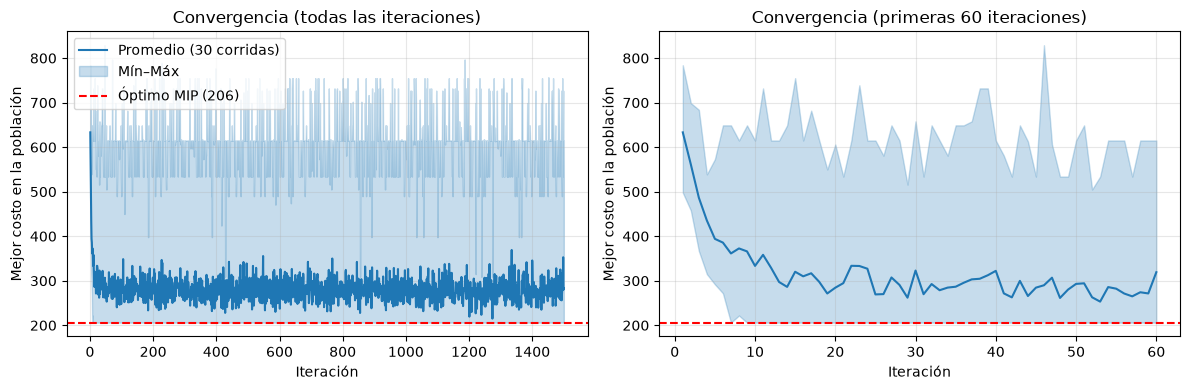

In [75]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(1, N_ITER + 1)

for ax, lim in zip(axs, [N_ITER, 60]):
    xs = x[:lim]
    ax.plot(xs, H.mean(axis=0)[:lim], label="Promedio (30 corridas)", color="tab:blue")
    ax.fill_between(xs, H.min(axis=0)[:lim], H.max(axis=0)[:lim],
                    alpha=0.25, color="tab:blue", label="Mín–Máx")
    ax.axhline(z_opt, color="red", linestyle="--", label=f"Óptimo MIP ({z_opt})")
    ax.set_xlabel("Iteración")
    ax.set_ylabel("Mejor costo en la población")
    ax.grid(alpha=0.3)
axs[0].set_title("Convergencia (todas las iteraciones)")
axs[1].set_title("Convergencia (primeras 60 iteraciones)")
axs[0].legend()
plt.tight_layout()
plt.savefig("../images/secuenciacion/convergencia.png", dpi=300, bbox_inches="tight")
plt.show()

C:\Users\hugo_\AppData\Local\Temp\ipykernel_26800\1583517812.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[1].boxplot(df_ga["Tiempo (s)"], vert=True)


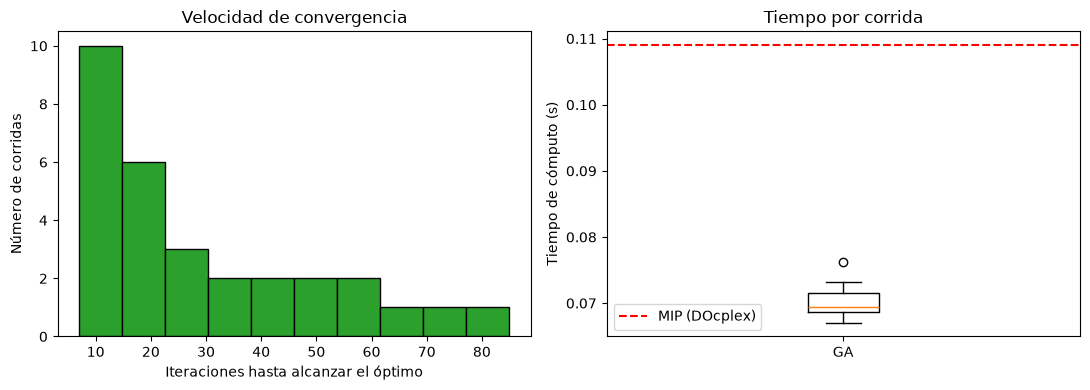

In [76]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].hist(df_ga["Iter. al óptimo"].dropna(), bins=10, color="tab:green", edgecolor="black")
axs[0].set_xlabel("Iteraciones hasta alcanzar el óptimo")
axs[0].set_ylabel("Número de corridas")
axs[0].set_title("Velocidad de convergencia")

axs[1].boxplot(df_ga["Tiempo (s)"], vert=True)
axs[1].set_xticklabels(["GA"])
axs[1].axhline(resultados_exactos["tiempo_segundos"], color="red", linestyle="--",
               label="MIP (DOcplex)")
axs[1].set_ylabel("Tiempo de cómputo (s)")
axs[1].set_title("Tiempo por corrida")
axs[1].legend()

plt.tight_layout()
plt.savefig("../images/secuenciacion/distribucion_ga.png", dpi=300, bbox_inches="tight")
plt.show()

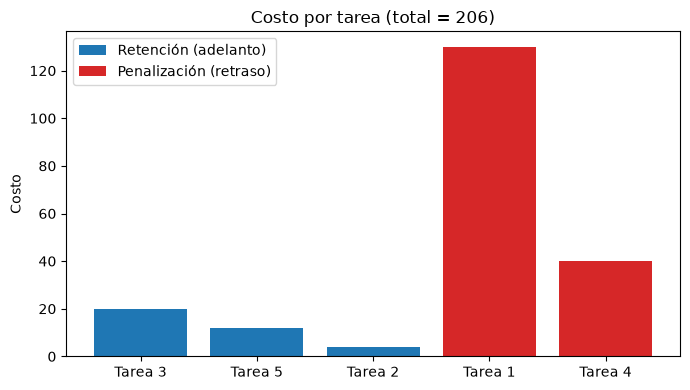

In [78]:
fig, ax = plt.subplots(figsize=(7, 4))
etiquetas = [f"Tarea {int(i)}" for i in prog_ga["Tarea"]]
ax.bar(etiquetas, prog_ga["Costo retención"], label="Retención (adelanto)", color="tab:blue")
ax.bar(etiquetas, prog_ga["Costo penalización"], bottom=prog_ga["Costo retención"],
       label="Penalización (retraso)", color="tab:red")
ax.set_ylabel("Costo")
ax.set_title(f"Costo por tarea (total = {prog_ga['Costo'].sum():.0f})")
ax.legend()
plt.tight_layout()
plt.savefig("../images/secuenciacion/costo_por_tarea.png", dpi=300, bbox_inches="tight")
plt.show()

Permutaciones evaluadas: 120
Costo mínimo: 206 | Secuencias óptimas: [(3, 5, 2, 1, 4)]
Tiempo: 0.0000 s
Costo promedio de una permutación al azar: 521.7
Probabilidad de acertar el óptimo al azar: 0.83%


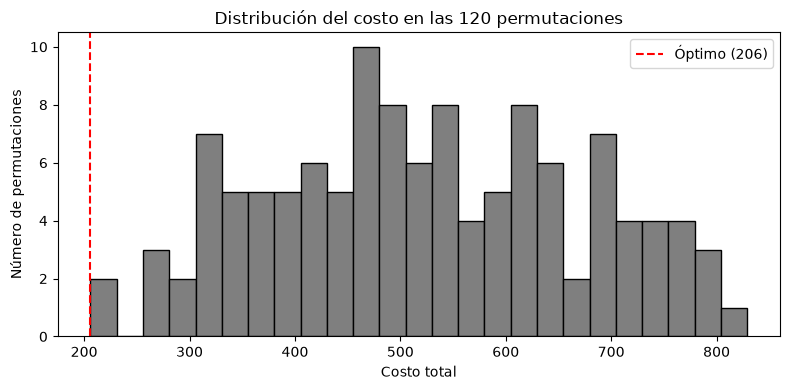

In [79]:
inicio = time.time()
todas = list(itertools.permutations(M))
costos_todas = np.array([objective_function(t, d, h, c, p) for p in todas])
tiempo_enum = time.time() - inicio

z_enum = costos_todas.min()
optimas = [p for p, z in zip(todas, costos_todas) if z == z_enum]
print(f"Permutaciones evaluadas: {len(todas)}")
print(f"Costo mínimo: {z_enum} | Secuencias óptimas: {optimas}")
print(f"Tiempo: {tiempo_enum:.4f} s")
print(f"Costo promedio de una permutación al azar: {costos_todas.mean():.1f}")
print(f"Probabilidad de acertar el óptimo al azar: {len(optimas)/len(todas):.2%}")

plt.figure(figsize=(8, 4))
plt.hist(costos_todas, bins=25, color="tab:gray", edgecolor="black")
plt.axvline(z_enum, color="red", linestyle="--", label=f"Óptimo ({z_enum:.0f})")
plt.xlabel("Costo total")
plt.ylabel("Número de permutaciones")
plt.title("Distribución del costo en las 120 permutaciones")
plt.legend()
plt.tight_layout()
plt.savefig("../images/secuenciacion/distribucion_permutaciones.png", dpi=300, bbox_inches="tight")
plt.show()

In [83]:
resultados_sens = []
for pm in [0.0, 0.01, 0.05, 0.10, 0.20]:
    costos = []
    for semilla in range(30):
        np.random.seed(semilla)
        _, val, *_ = ejecutar_genetico(t, d, h, c, M, num_vectores=POB,
                                       num_iteraciones=30, tasa_mutacion=pm)
        costos.append(val)
    costos = np.array(costos)
    resultados_sens.append({"P_m": pm, "Costo promedio": costos.mean(),
                            "Tasa de éxito (%)": (costos == z_opt).mean() * 100})
print(pd.DataFrame(resultados_sens).to_string(index=False))

 P_m  Costo promedio  Tasa de éxito (%)
0.00      259.900000          26.666667
0.01      245.800000          46.666667
0.05      218.333333          73.333333
0.10      214.066667          86.666667
0.20      212.466667          90.000000


In [80]:
comparacion = pd.DataFrame([
    {"Método": "DOcplex (MIP)", "Mejor": costo_optimo, "Promedio": np.nan, "Peor": np.nan,
     "Desv. est.": np.nan, "Tiempo (s)": resultados_exactos["tiempo_segundos"],
     "Gap (%)": 0.0, "Secuencia": resultados_exactos["secuencia"]},
    {"Método": "Algoritmo genético", "Mejor": df_ga["Costo"].min(),
     "Promedio": df_ga["Costo"].mean(), "Peor": df_ga["Costo"].max(),
     "Desv. est.": df_ga["Costo"].std(), "Tiempo (s)": df_ga["Tiempo (s)"].mean(),
     "Gap (%)": (df_ga["Costo"].min() - z_opt) / z_opt * 100, "Secuencia": sec_ga},
    {"Método": "Enumeración exhaustiva", "Mejor": z_enum, "Promedio": np.nan, "Peor": np.nan,
     "Desv. est.": np.nan, "Tiempo (s)": tiempo_enum, "Gap (%)": 0.0,
     "Secuencia": list(optimas[0])},
])
print(comparacion.to_string(index=False))
# print(comparacion.drop(columns="Secuencia").to_latex(index=False, float_format="%.3f", na_rep="--"))

                Método  Mejor  Promedio  Peor  Desv. est.  Tiempo (s)  Gap (%)       Secuencia
         DOcplex (MIP)  206.0       NaN   NaN         NaN    0.109000      0.0 [3, 5, 2, 1, 4]
    Algoritmo genético  206.0     206.0 206.0         0.0    0.070025      0.0 [3, 5, 2, 1, 4]
Enumeración exhaustiva  206.0       NaN   NaN         NaN    0.000000      0.0 [3, 5, 2, 1, 4]
